# PDZ3 Baselines over HMC-Resampled FLIP Targets

Generate posterior target datasets, reproduce FLIP2-style one-hot Ridge. Placeholder code to add fixed zero-shot likelihood baselines when their cached scores become available.

See `notes/flip2-zero-shot-and-baselines.md` for general notes on this notebook, you can the score definitions and paper pointers especially towards the end (there is a lot going on in the doc right now, I will clean it up soon).

In [17]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import scripts.run_pdz_flip_baselines as flip_baselines

flip_baselines = importlib.reload(flip_baselines)

from scripts.pdz_trans_hmc_flip_replicates import (
    DEFAULT_HMC_PATHS,
    PROXY_COLUMNS,
    available_hmc_draws,
    make_hmc_flip_replicates,
)
from scripts.run_pdz_flip_baselines import (
    DEFAULT_SCORE_PATH,
    benchmark_replicates,
    load_zero_shot_scores,
    proxy_correlations,
    random_split_learning_curves,
    rank_space_compatibility,
    summarize,
    summarize_learning_curves,
    summarize_learning_curves_pooled,
)

## 1. Generate HMC target replicates

`MAX_HMC_DRAWS` is the common number of `(chain, draw)` samples available in both trans fits. Set `N = MAX_HMC_DRAWS` to use every draw exactly once; smaller values use a sample without replacement.

Each generated dataset retains `log_r_mean`, the three posterior-predictive input counts, the three posterior-predictive output counts, and count-derived proxy fitness columns.

Using all draws means 16,000 DataFrames.  This is reasonable for the single prescribed-split fit per draw. The learning-curve section is much more expensive and is capped separately by `MAX_CURVE_HMC_REPLICATES` (default 200).

In [2]:
N = 100
SEED = 23

missing_hmc = [path for path in DEFAULT_HMC_PATHS.values() if not path.exists()]
if missing_hmc:
    MAX_HMC_DRAWS = None
    replicate_datasets = None
    print("TODO: download the missing HMC file(s):")
    for path in missing_hmc:
        print(f"  {path}")
else:
    MAX_HMC_DRAWS = available_hmc_draws()
    print(f"Maximum common HMC draws: {MAX_HMC_DRAWS:,}")
    N = MAX_HMC_DRAWS
    # Set N = MAX_HMC_DRAWS above to use every draw in natural stacked order.
    replicate_datasets = make_hmc_flip_replicates(N, seed=SEED)
    print(f"Generated {len(replicate_datasets)} datasets with {len(replicate_datasets[0])} rows each.")

Maximum common HMC draws: 16,000


c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness\scripts\pdz_trans_hmc_flip_replicates.py:126: RuntimeWarning: invalid value encountered in multiply
  np.where(valid, replicate_fitness * weights, 0.0).sum(axis=1),
c:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness\scripts\pdz_trans_hmc_flip_replicates.py:126: RuntimeWarning: invalid value encountered in multiply
  np.where(valid, replicate_fitness * weights, 0.0).sum(axis=1),


Generated 16000 datasets with 734 rows each.


## 2. Compare reported and proxy fitness

For every joint HMC draw, calculate the Spearman correlation across FLIP variants between the published fitness and each proxy:

- **Posterior `log_r_mean`:** the existing HMC target used by the baselines.
- **Posterior-predictive count ratio:** total output count divided by total input count across the three generated experimental replicates.
- **DiMSum-style count fitness:** replicate-wise log enrichment relative to wild-type, merged with inverse count-variance weights. This reproduces the count-derived core of DiMSum, but not its fitted replicate error model or the paper's final cross-library linear calibration, whose coefficients are not available here.

Each point below is one complete HMC replicate dataset. Correlations use every variant with finite published and proxy values.

Reference fitness: data/single_to_double_from_flip_repo.csv target, aligned by sequence


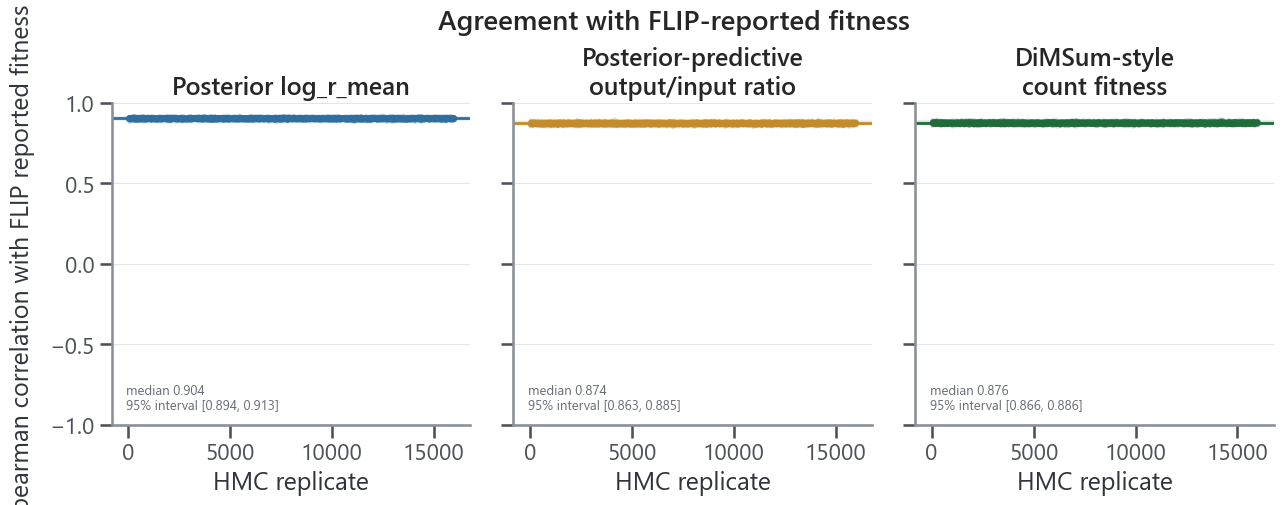

,proxy,n,median,lower,upper
0,proxy_log_r_mean,16000,0.903930,0.893854,0.913463
1,proxy_count_ratio,16000,0.874149,0.863104,0.884940
2,proxy_dimsum_fitness,16000,0.876237,0.865934,0.886499


In [13]:
if replicate_datasets is None:
    proxy_correlation_results = proxy_correlation_summary = None
    print("Generate HMC replicates before comparing fitness proxies.")
else:
    proxy_correlation_results = proxy_correlations(replicate_datasets)
    assert proxy_correlation_results["reference"].eq("FLIP reported target").all()
    print("Reference fitness: data/single_to_double_from_flip_repo.csv target, aligned by sequence")
    proxy_correlation_summary = (
        proxy_correlation_results.groupby("proxy", sort=False)["spearman"]
        .agg(
            n="count",
            median="median",
            lower=lambda values: values.quantile(0.025),
            upper=lambda values: values.quantile(0.975),
        )
        .reset_index()
    )

    proxy_labels = {
        "proxy_log_r_mean": "Posterior log_r_mean",
        "proxy_count_ratio": "Posterior-predictive\noutput/input ratio",
        "proxy_dimsum_fitness": "DiMSum-style\ncount fitness",
    }
    proxy_colors = {
        "proxy_log_r_mean": "#2F6F9F",
        "proxy_count_ratio": "#C28B2C",
        "proxy_dimsum_fitness": "#1F6B3A",
    }

    sns.set_theme(
        context="talk",
        style="ticks",
        font="Segoe UI",
        rc={
            "axes.titleweight": "semibold",
            "axes.labelcolor": "#30343B",
            "axes.edgecolor": "#8A8F98",
            "grid.color": "#E2E5E9",
            "grid.linewidth": 0.8,
            "xtick.color": "#4E535B",
            "ytick.color": "#4E535B",
        },
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
    for ax, proxy in zip(axes, proxy_labels):
        values = proxy_correlation_results[proxy_correlation_results["proxy"] == proxy]
        interval = proxy_correlation_summary[proxy_correlation_summary["proxy"] == proxy].iloc[0]
        sns.scatterplot(
            data=values,
            x="replicate",
            y="spearman",
            color=proxy_colors[proxy],
            alpha=0.20,
            s=10,
            linewidth=0,
            rasterized=True,
            ax=ax,
        )
        ax.axhspan(interval["lower"], interval["upper"], color=proxy_colors[proxy], alpha=0.10)
        ax.axhline(interval["median"], color=proxy_colors[proxy], linewidth=2.0)
        ax.set(
            title=proxy_labels[proxy],
            xlabel="HMC replicate",
            ylabel="",
            ylim=(-1.0, 1.0),
        )
        ax.text(
            0.04,
            0.05,
            f"median {interval['median']:.3f}\n95% interval [{interval['lower']:.3f}, {interval['upper']:.3f}]",
            transform=ax.transAxes,
            fontsize=9.5,
            color="#686D75",
        )
        ax.grid(axis="y", visible=True)
        ax.grid(axis="x", visible=False)
        sns.despine(ax=ax)

    axes[0].set_ylabel("Spearman correlation with FLIP reported fitness", labelpad=10)
    fig.suptitle("Agreement with FLIP-reported fitness", fontsize=20, fontweight="semibold")
    fig.subplots_adjust(top=0.80, bottom=0.18, wspace=0.12)
    plt.show()
    display(proxy_correlation_summary)

## 3. Rank-space compatibility of reported fitness

The correlation plot above asks how closely each individual HMC draw agrees with FLIP. This analysis instead asks whether the complete FLIP ranking is typical relative to variation among HMC draws.

For each proxy, convert every draw and the sequence-aligned FLIP target to ranks between 0 and 1. Split HMC draws reproducibly into equal reference and calibration sets (`seed=23`). Reference draws define each variant's mean rank and rank SD; held-out calibration draws define the distribution expected for a new HMC draw.

Two complementary diagnostics are reported:

- **Standardized rank discrepancy:** mean squared difference from the reference mean rank, divided variant-by-variant by reference rank variance. A high FLIP percentile means FLIP is farther from the HMC rank center than most held-out draws.
- **Consensus Spearman:** correlation with the consensus ranking learned from reference draws. A low FLIP percentile means FLIP is less consensus-like than most held-out draws.

The rank-SD floor is one rank step, preventing effectively fixed ranks from producing unstable divisions. For proxies with missing values, one fixed complete-case sequence set is used across all draws. Marginal 50%, 80%, and 95% rank-interval coverage and the largest variant-level contributions are retained for interpretation. These are compatibility diagnostics, not formal posterior predictive p-values.

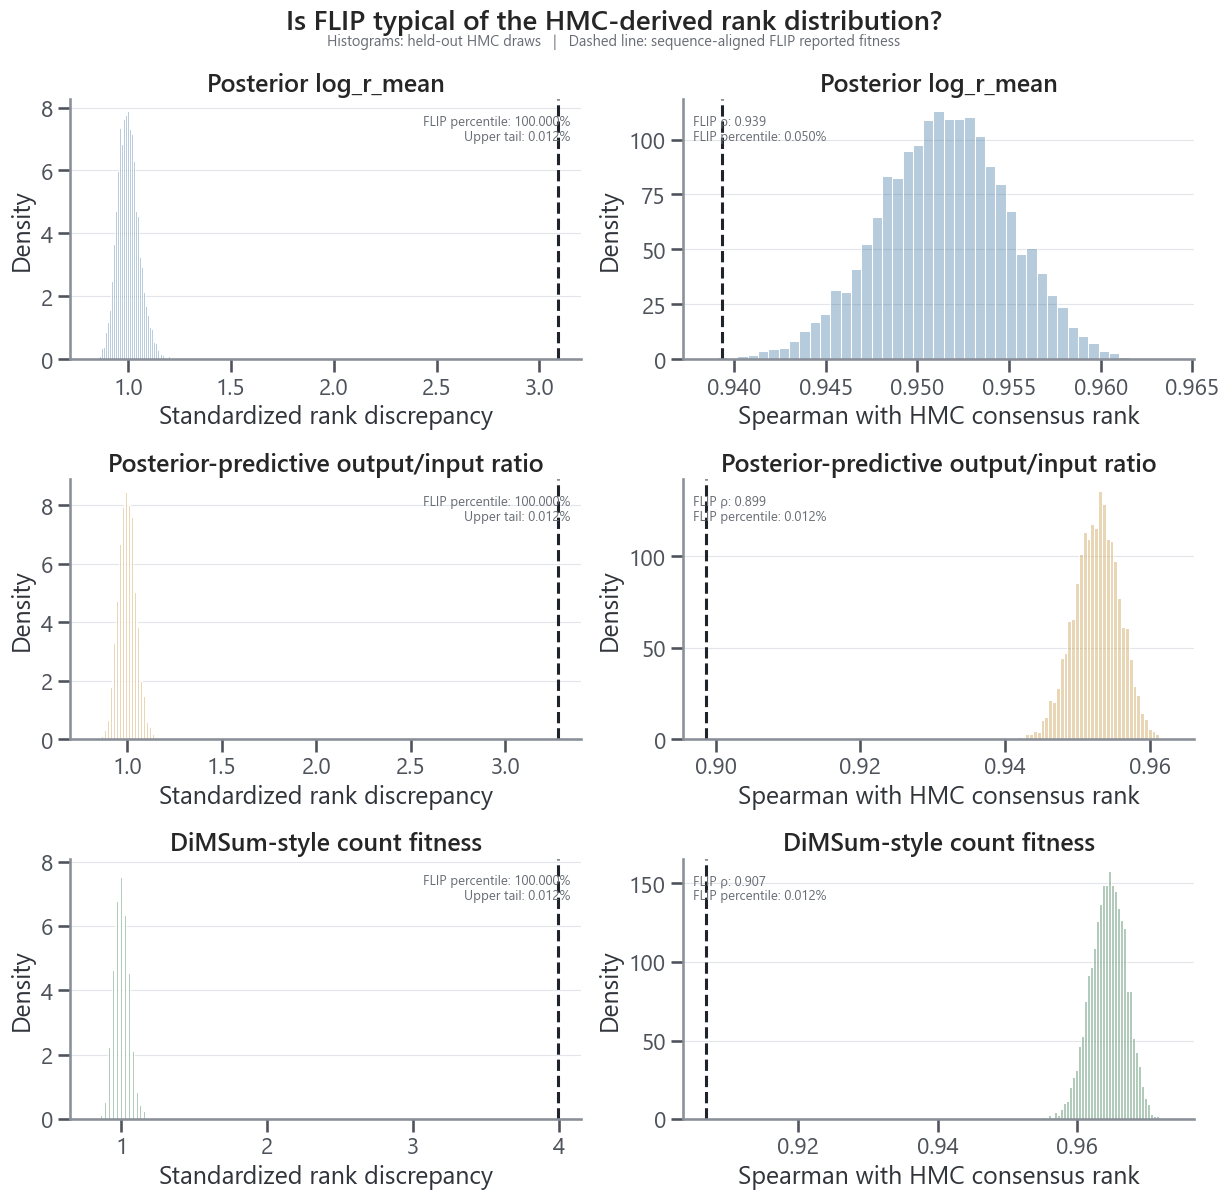

,proxy,n_reference,n_calibration,n_variants,n_excluded_incomplete,rank_sd_floor,n_sd_floored,flip_consensus_spearman,consensus_spearman_percentile,flip_standardized_discrepancy,discrepancy_percentile,upper_tail_fraction,coverage_50,coverage_80,coverage_95
0,proxy_log_r_mean,8000,8000,734,0,0.001364,0,0.939330,0.000500,3.089554,1.0,0.000125,0.434605,0.647139,0.775204
1,proxy_count_ratio,8000,8000,734,0,0.001364,2,0.898726,0.000125,3.277155,1.0,0.000125,0.420981,0.584469,0.738420
2,proxy_dimsum_fitness,8000,8000,729,5,0.001374,2,0.906804,0.000125,3.990762,1.0,0.000125,0.386831,0.587106,0.732510


,proxy,sequence,set,validation,flip_reported_fitness,flip_rank,hmc_mean_rank,hmc_rank_sd,standardized_rank_residual,squared_contribution
0,proxy_count_ratio,GEEDIPREPRRIVIHVGSTGLGFNIVGGEDGEGIFISFILAGGPAD...,test,False,-0.421281,0.335607,0.565822,0.026516,-8.682262,75.381678
1,proxy_count_ratio,GEEDIPREPRRIVCHRGSTGLGFNIVGGEDGEGIFISFILAGGPAD...,test,False,-0.315561,0.541610,0.732311,0.030610,-6.229960,38.812400
2,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLRFNIVGGEDGEGIFISFILAGGPAD...,test,False,-0.412991,0.360164,0.572303,0.037573,-5.646101,31.878454
3,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFNIVGGEIGEGIFISFILAGGPAD...,test,False,-0.419146,0.339700,0.550528,0.037779,-5.580621,31.143333
4,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFNIRGGEDGEGIFISFILAGGPAD...,test,False,-0.390694,0.407913,0.586997,0.032372,-5.532110,30.604237
5,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFCIVGGEDGEGIFISFILAGGPAD...,test,False,0.036752,0.979536,0.703403,0.053288,5.181914,26.852232
6,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDNEGIFISFILAGGPAD...,test,False,-0.181711,0.732606,0.858715,0.024614,-5.123532,26.250578
7,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFNIVGGRDGEGIFISFILAGGPAD...,test,False,-0.391900,0.406548,0.598574,0.038132,-5.035855,25.359840
8,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFIAFILAGGPAD...,test,False,-0.282620,0.585266,0.706277,0.024201,-5.000211,25.002108
9,proxy_count_ratio,GEEDIPREPRRIVIHRGSTGLGFNIVGGEDGEGIFIQFILAGGPAD...,test,False,0.000535,0.956344,0.990824,0.007016,-4.914373,24.151066


In [16]:
if replicate_datasets is None:
    rank_compatibility_summary = rank_calibration_scores = rank_variant_diagnostics = None
    print("Generate HMC replicates before running rank-space compatibility checks.")
else:
    (
        rank_compatibility_summary,
        rank_calibration_scores,
        rank_variant_diagnostics,
    ) = rank_space_compatibility(
        replicate_datasets,
        reference_fraction=0.5,
        seed=SEED,
    )

    rank_proxy_labels = {
        "proxy_log_r_mean": "Posterior log_r_mean",
        "proxy_count_ratio": "Posterior-predictive output/input ratio",
        "proxy_dimsum_fitness": "DiMSum-style count fitness",
    }
    rank_proxy_colors = {
        "proxy_log_r_mean": "#2F6F9F",
        "proxy_count_ratio": "#C28B2C",
        "proxy_dimsum_fitness": "#1F6B3A",
    }

    sns.set_theme(
        context="talk",
        style="ticks",
        font="Segoe UI",
        rc={
            "axes.titleweight": "semibold",
            "axes.labelcolor": "#30343B",
            "axes.edgecolor": "#8A8F98",
            "grid.color": "#E2E5E9",
            "grid.linewidth": 0.8,
            "xtick.color": "#4E535B",
            "ytick.color": "#4E535B",
        },
    )

    fig, axes = plt.subplots(3, 2, figsize=(14.5, 12.0))
    for row, proxy in enumerate(rank_proxy_labels):
        scores = rank_calibration_scores[rank_calibration_scores["proxy"] == proxy]
        result = rank_compatibility_summary[rank_compatibility_summary["proxy"] == proxy].iloc[0]
        color = rank_proxy_colors[proxy]

        sns.histplot(
            data=scores,
            x="standardized_discrepancy",
            bins=45,
            stat="density",
            color=color,
            alpha=0.35,
            edgecolor=None,
            ax=axes[row, 0],
        )
        axes[row, 0].axvline(
            result["flip_standardized_discrepancy"],
            color="#20242A",
            linewidth=2.2,
            linestyle="--",
        )
        axes[row, 0].set(
            title=rank_proxy_labels[proxy],
            xlabel="Standardized rank discrepancy",
            ylabel="Density",
        )
        axes[row, 0].text(
            0.98,
            0.94,
            f"FLIP percentile: {result['discrepancy_percentile']:.3%}\nUpper tail: {result['upper_tail_fraction']:.3%}",
            transform=axes[row, 0].transAxes,
            ha="right",
            va="top",
            fontsize=9.5,
            color="#686D75",
        )

        sns.histplot(
            data=scores,
            x="consensus_spearman",
            bins=45,
            stat="density",
            color=color,
            alpha=0.35,
            edgecolor=None,
            ax=axes[row, 1],
        )
        axes[row, 1].axvline(
            result["flip_consensus_spearman"],
            color="#20242A",
            linewidth=2.2,
            linestyle="--",
        )
        axes[row, 1].set(
            title=rank_proxy_labels[proxy],
            xlabel="Spearman with HMC consensus rank",
            ylabel="Density",
        )
        axes[row, 1].text(
            0.02,
            0.94,
            f"FLIP ρ: {result['flip_consensus_spearman']:.3f}\nFLIP percentile: {result['consensus_spearman_percentile']:.3%}",
            transform=axes[row, 1].transAxes,
            ha="left",
            va="top",
            fontsize=9.5,
            color="#686D75",
        )

        for ax in axes[row]:
            ax.grid(axis="y", visible=True)
            ax.grid(axis="x", visible=False)
            sns.despine(ax=ax)

    fig.suptitle(
        "Is FLIP typical of the HMC-derived rank distribution?",
        fontsize=20,
        fontweight="semibold",
        y=0.995,
    )
    fig.text(
        0.5,
        0.965,
        "Histograms: held-out HMC draws   |   Dashed line: sequence-aligned FLIP reported fitness",
        ha="center",
        fontsize=10.5,
        color="#686D75",
    )
    fig.subplots_adjust(top=0.92, bottom=0.07, hspace=0.46, wspace=0.20)
    plt.show()

    rank_summary_columns = [
        "proxy",
        "n_reference",
        "n_calibration",
        "n_variants",
        "n_excluded_incomplete",
        "rank_sd_floor",
        "n_sd_floored",
        "flip_consensus_spearman",
        "consensus_spearman_percentile",
        "flip_standardized_discrepancy",
        "discrepancy_percentile",
        "upper_tail_fraction",
        "coverage_50",
        "coverage_80",
        "coverage_95",
    ]
    display(rank_compatibility_summary[rank_summary_columns])

    top_rank_disagreements = (
        rank_variant_diagnostics.sort_values(
            ["proxy", "squared_contribution"],
            ascending=[True, False],
        )
        .groupby("proxy", sort=False)
        .head(10)
        .reset_index(drop=True)
    )
    display(
        top_rank_disagreements[
            [
                "proxy",
                "sequence",
                "set",
                "validation",
                "flip_reported_fitness",
                "flip_rank",
                "hmc_mean_rank",
                "hmc_rank_sd",
                "standardized_rank_residual",
                "squared_contribution",
            ]
        ]
    )

## 4. Load optional zero-shot likelihood scores

`data/zero_shot/pdz3_scores.csv` is intentionally absent until manuscript-compatible ESM2, CARP, or Dayhoff scores are generated. Scores are sequence-only and are reused across all HMC target replicates.

In [19]:
if replicate_datasets is None:
    zero_shot_scores = None
    print("Generate HMC replicates before loading aligned zero-shot scores.")
elif not DEFAULT_SCORE_PATH.exists():
    zero_shot_scores = None
    print(f"TODO: populate {DEFAULT_SCORE_PATH}")
    print("Create an empty template with: python scripts/run_pdz_flip_baselines.py --write-zero-shot-template")
else:
    zero_shot_scores = load_zero_shot_scores(
        DEFAULT_SCORE_PATH,
        replicate_datasets[0]["sequence"],
    )
    print("Available score columns:", zero_shot_scores.columns.drop("sequence").tolist())

TODO: populate C:\Users\t-renatob\OneDrive - Microsoft\Desktop\RenatoBerlinghieri\prob-protein-fitness\data\zero_shot\pdz3_scores.csv
Create an empty template with: python scripts/run_pdz_flip_baselines.py --write-zero-shot-template


## 5. Run Ridge baselines on all three HMC-derived targets

For each proxy, report the same published-target reference and a distribution over all `N` HMC target datasets. Ridge is fitted and evaluated against the selected target definition within each draw:

- posterior `log_r_mean`;
- posterior-predictive output/input count ratio;
- DiMSum-style count fitness.

The prescribed FLIP split always uses 124 non-validation training rows and 579 test rows before filtering non-finite proxy values. The output records the finite train/test count for every fit. If cached likelihood scores become available, the same loop also evaluates Ridge with one-hot plus likelihood features.

In [20]:
if replicate_datasets is None:
    results = summary = None
    print("TODO: rerun after both HMC files are available.")
else:
    results = pd.concat(
        [
            benchmark_replicates(
                replicate_datasets,
                target_column=target_proxy,
                zero_shot_scores=zero_shot_scores,
                alpha=10.0,
            )
            for target_proxy in PROXY_COLUMNS
        ],
        ignore_index=True,
    )
    summary = summarize(results)
    display(summary)

,target_proxy,target_source,model,evaluation_set,n,mean,median,std,lower,upper,paper_spearman,difference_from_paper
0,proxy_count_ratio,hmc,Ridge (one-hot),test,16000,0.564823,0.561718,0.026319,0.521276,0.613385,NaN,NaN
1,proxy_count_ratio,published,Ridge (one-hot),test,1,0.479650,0.479650,NaN,0.479650,0.479650,0.476,0.00365
2,proxy_dimsum_fitness,hmc,Ridge (one-hot),test,16000,0.420843,0.420868,0.013517,0.394156,0.447335,NaN,NaN
3,proxy_dimsum_fitness,published,Ridge (one-hot),test,1,0.479650,0.479650,NaN,0.479650,0.479650,0.476,0.00365
4,proxy_log_r_mean,hmc,Ridge (one-hot),test,16000,0.538804,0.538078,0.016262,0.508807,0.572354,NaN,NaN
5,proxy_log_r_mean,published,Ridge (one-hot),test,1,0.479650,0.479650,NaN,0.479650,0.479650,0.476,0.00365


## 6. FLIP2-style random-split learning curves for all proxies

For each of the three target proxies, reproduce the same two protocols:

- **Random-split learning curves:** 10 logarithmically spaced training sizes from 50 to 80% of all 734 variants and five fixed random partitions per size (`seed=23`).
- **Prescribed FLIP split point:** 124 non-validation training rows, 31 validation rows, and 579 test rows before filtering non-finite proxy values.

The expensive learning curves use the same reproducible subset of at most `MAX_CURVE_HMC_REPLICATES` draws for every proxy, and the same train/test partitions across proxies and draws. This makes differences among rows attributable to the target definition rather than different posterior samples or data partitions.

In the figure, rows are target proxies. The left column averages the five partition correlations within each HMC draw before taking quantiles across draws, emphasizing target uncertainty. The right column pools all `5N` correlations, combining target and partition variation.

In [21]:
N_TRAINING_SIZES = 10
N_SPLIT_REPEATS = 5
MAX_CURVE_HMC_REPLICATES = 200
CURVE_HMC_REPLICATES = min(len(replicate_datasets), MAX_CURVE_HMC_REPLICATES)

curve_rng = np.random.default_rng(SEED)
curve_draw_indices = np.sort(
    curve_rng.choice(
        len(replicate_datasets),
        size=CURVE_HMC_REPLICATES,
        replace=False,
    )
)
curve_datasets = [replicate_datasets[index] for index in curve_draw_indices]

n_curve_fits = (
    len(PROXY_COLUMNS)
    * (1 + CURVE_HMC_REPLICATES)
    * N_TRAINING_SIZES
    * N_SPLIT_REPEATS
)
print(
    f"Learning curves: {len(PROXY_COLUMNS)} proxies, "
    f"{CURVE_HMC_REPLICATES:,} shared HMC draws, {N_TRAINING_SIZES} sizes, "
    f"{N_SPLIT_REPEATS} splits per size = {n_curve_fits:,} Ridge fits."
)

curve_results = pd.concat(
    [
        random_split_learning_curves(
            curve_datasets,
            target_column=target_proxy,
            zero_shot_scores=zero_shot_scores,
            alpha=10.0,
            min_train=50,
            max_fraction=0.8,
            n_training_sizes=N_TRAINING_SIZES,
            n_split_repeats=N_SPLIT_REPEATS,
            split_seed=23,
        )
        for target_proxy in PROXY_COLUMNS
    ],
    ignore_index=True,
)
curve_summary = summarize_learning_curves(curve_results)
curve_summary_pooled = summarize_learning_curves_pooled(curve_results)

print("Target uncertainty after averaging split repeats:")
display(curve_summary)
print("Pooled target and partition variation:")
display(curve_summary_pooled)

Learning curves: 3 proxies, 200 shared HMC draws, 10 sizes, 5 splits per size = 30,150 Ridge fits.
Target uncertainty after averaging split repeats:


,target_source,model,n_train,n,mean,median,lower,upper,uncertainty_source,target_proxy
0,hmc,Ridge (one-hot),49,200,0.645411,0.645293,0.628109,0.664073,HMC targets (split repeats averaged),proxy_count_ratio
1,hmc,Ridge (one-hot),65,200,0.644598,0.643968,0.628066,0.660557,HMC targets (split repeats averaged),proxy_count_ratio
2,hmc,Ridge (one-hot),86,200,0.641988,0.642197,0.622408,0.660068,HMC targets (split repeats averaged),proxy_count_ratio
3,hmc,Ridge (one-hot),113,200,0.654879,0.654385,0.633607,0.675269,HMC targets (split repeats averaged),proxy_count_ratio
4,hmc,Ridge (one-hot),149,200,0.645393,0.644937,0.626488,0.668331,HMC targets (split repeats averaged),proxy_count_ratio
5,hmc,Ridge (one-hot),196,200,0.666147,0.666714,0.648468,0.682719,HMC targets (split repeats averaged),proxy_count_ratio
6,hmc,Ridge (one-hot),258,200,0.671092,0.671432,0.656492,0.688207,HMC targets (split repeats averaged),proxy_count_ratio
7,hmc,Ridge (one-hot),339,200,0.694916,0.694885,0.676523,0.711549,HMC targets (split repeats averaged),proxy_count_ratio
8,hmc,Ridge (one-hot),446,200,0.698434,0.698817,0.679438,0.715098,HMC targets (split repeats averaged),proxy_count_ratio
9,hmc,Ridge (one-hot),587,200,0.687347,0.688165,0.663015,0.708619,HMC targets (split repeats averaged),proxy_count_ratio


Pooled target and partition variation:


,target_proxy,target_source,model,n_train,n,mean,median,lower,upper,uncertainty_source
0,proxy_count_ratio,hmc,Ridge (one-hot),49,1000,0.645411,0.649945,0.589579,0.678121,HMC targets + random partitions (pooled)
1,proxy_count_ratio,hmc,Ridge (one-hot),65,1000,0.644598,0.649790,0.603927,0.677351,HMC targets + random partitions (pooled)
2,proxy_count_ratio,hmc,Ridge (one-hot),86,1000,0.641988,0.641848,0.614000,0.670943,HMC targets + random partitions (pooled)
3,proxy_count_ratio,hmc,Ridge (one-hot),113,1000,0.654879,0.658247,0.605282,0.692840,HMC targets + random partitions (pooled)
4,proxy_count_ratio,hmc,Ridge (one-hot),149,1000,0.645393,0.645899,0.615069,0.676313,HMC targets + random partitions (pooled)
5,proxy_count_ratio,hmc,Ridge (one-hot),196,1000,0.666147,0.666364,0.641124,0.693360,HMC targets + random partitions (pooled)
6,proxy_count_ratio,hmc,Ridge (one-hot),258,1000,0.671092,0.669155,0.635954,0.715863,HMC targets + random partitions (pooled)
7,proxy_count_ratio,hmc,Ridge (one-hot),339,1000,0.694916,0.695682,0.658060,0.730653,HMC targets + random partitions (pooled)
8,proxy_count_ratio,hmc,Ridge (one-hot),446,1000,0.698434,0.697192,0.654913,0.748010,HMC targets + random partitions (pooled)
9,proxy_count_ratio,hmc,Ridge (one-hot),587,1000,0.687347,0.688389,0.639463,0.733472,HMC targets + random partitions (pooled)


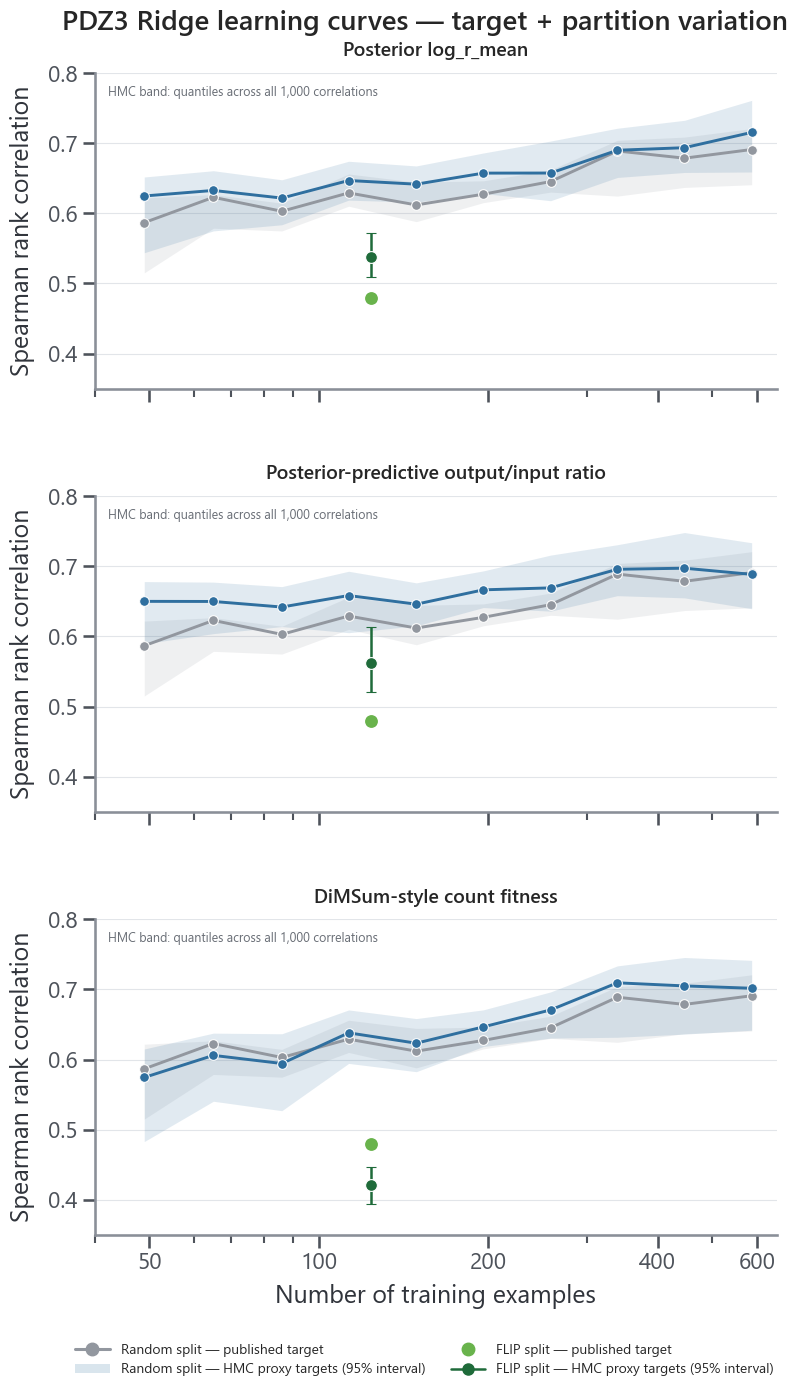

In [26]:
sns.set_theme(
    context="talk",
    style="ticks",
    font="Segoe UI",
    rc={
        "axes.titleweight": "semibold",
        "axes.labelcolor": "#30343B",
        "axes.edgecolor": "#8A8F98",
        "grid.color": "#E2E5E9",
        "grid.linewidth": 0.8,
        "xtick.color": "#4E535B",
        "ytick.color": "#4E535B",
    },
)

# Choose "pooled" for target + split variation or "draw_mean" for target-only uncertainty.
CURVE_AGGREGATION = "pooled"
AGGREGATION_OPTIONS = {
    "draw_mean": {
        "summary": curve_summary,
        "label": "Target uncertainty",
        "note": "HMC band: quantiles across draws\nafter averaging 5 split repeats",
    },
    "pooled": {
        "summary": curve_summary_pooled,
        "label": "Target + partition variation",
        "note": f"HMC band: quantiles across all {CURVE_HMC_REPLICATES * N_SPLIT_REPEATS:,} correlations",
    },
}
if CURVE_AGGREGATION not in AGGREGATION_OPTIONS:
    raise ValueError(
        f"CURVE_AGGREGATION must be one of {tuple(AGGREGATION_OPTIONS)}, "
        f"not {CURVE_AGGREGATION!r}."
    )
aggregation = AGGREGATION_OPTIONS[CURVE_AGGREGATION]
plot_curve_summary = aggregation["summary"]

COLORS = {
    "published": "#92979F",
    "hmc": "#2F6F9F",
    "split_published": "#69B34C",
    "split_hmc": "#1F6B3A",
}
MODEL_STYLES = {
    "Ridge (one-hot)": ("o", "-"),
    "Ridge (one-hot + likelihoods)": ("X", "--"),
}
TARGET_LABELS = {
    "proxy_log_r_mean": "Posterior log_r_mean",
    "proxy_count_ratio": "Posterior-predictive output/input ratio",
    "proxy_dimsum_fitness": "DiMSum-style count fitness",
}
models = list(plot_curve_summary["model"].unique())
prescribed_n_train = int(
    (
        replicate_datasets[0]["set"].eq("train")
        & ~replicate_datasets[0]["validation"].astype(bool)
    ).sum()
)


def plot_proxy_learning_panel(ax, target_proxy):
    for model_index, model in enumerate(models):
        marker, linestyle = MODEL_STYLES.get(model, ("o", "-"))
        for target_source in ("published", "hmc"):
            curve = plot_curve_summary[
                (plot_curve_summary["target_proxy"] == target_proxy)
                & (plot_curve_summary["model"] == model)
                & (plot_curve_summary["target_source"] == target_source)
            ].sort_values("n_train")
            color = COLORS[target_source]
            sns.lineplot(
                data=curve,
                x="n_train",
                y="median",
                marker=marker,
                markersize=7,
                linestyle=linestyle,
                linewidth=2.1,
                color=color,
                legend=False,
                ax=ax,
            )
            ax.fill_between(
                curve["n_train"].to_numpy(dtype=float),
                curve["lower"].to_numpy(dtype=float),
                curve["upper"].to_numpy(dtype=float),
                color=color,
                alpha=0.14,
                linewidth=0,
            )

        published = summary[
            (summary["target_proxy"] == target_proxy)
            & (summary["model"] == model)
            & (summary["target_source"] == "published")
            & (summary["evaluation_set"] == "test")
        ].iloc[0]
        hmc = summary[
            (summary["target_proxy"] == target_proxy)
            & (summary["model"] == model)
            & (summary["target_source"] == "hmc")
            & (summary["evaluation_set"] == "test")
        ].iloc[0]
        published_mean = float(np.asarray(published["mean"]).item())
        hmc_median = float(np.asarray(hmc["median"]).item())
        hmc_lower = float(np.asarray(hmc["lower"]).item())
        hmc_upper = float(np.asarray(hmc["upper"]).item())
        x_offset = 1 + 0.035 * model_index

        ax.scatter(
            prescribed_n_train / x_offset,
            published_mean,
            marker=marker,
            s=105,
            color=COLORS["split_published"],
            edgecolor="white",
            linewidth=1,
            zorder=5,
        )
        ax.errorbar(
            prescribed_n_train * x_offset,
            hmc_median,
            yerr=[[hmc_median - hmc_lower], [hmc_upper - hmc_median]],
            marker=marker,
            markersize=8.5,
            color=COLORS["split_hmc"],
            markeredgecolor="white",
            markeredgewidth=0.8,
            capsize=3.5,
            linewidth=1.8,
            zorder=5,
        )

    published_zero_shot = results[
        (results["target_proxy"] == target_proxy)
        & (results["target_source"] == "published")
        & (results["evaluation_set"] == "test")
        & results["model"].str.contains("zero-shot")
    ]
    if not published_zero_shot.empty:
        best_zero_shot = published_zero_shot.loc[published_zero_shot["spearman"].idxmax()]
        ax.axhline(
            float(np.asarray(best_zero_shot["spearman"]).item()),
            color="#6F737A",
            linewidth=1.2,
            linestyle=":",
        )

    ax.set_xscale("log")
    ax.set_xlim(40, 650)
    ax.set_xticks([50, 100, 200, 400, 600], labels=["50", "100", "200", "400", "600"])
    ax.set_ylim(0.35, 0.8)
    ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8])
    ax.set_xlabel("Number of training examples", labelpad=7)
    ax.set_ylabel("Spearman rank correlation", labelpad=9)
    ax.set_title(TARGET_LABELS[target_proxy], fontsize=14, pad=12)
    ax.text(
        0.02,
        0.96,
        aggregation["note"],
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=9,
        color="#686D75",
    )
    ax.grid(axis="y", visible=True)
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)


fig, axes = plt.subplots(3, 1, figsize=(8.8, 14.0), sharex=True, sharey=True)
for ax, target_proxy in zip(axes, PROXY_COLUMNS):
    plot_proxy_learning_panel(ax, target_proxy)

legend_handles = [
    Line2D([0], [0], color=COLORS["published"], marker="o", linewidth=2.2, label="Random split — published target"),
    Patch(facecolor=COLORS["hmc"], alpha=0.18, edgecolor="none", label="Random split — HMC proxy targets (95% interval)"),
    Line2D([0], [0], color=COLORS["split_published"], marker="o", linestyle="none", markersize=9, label="FLIP split — published target"),
    Line2D([0], [0], color=COLORS["split_hmc"], marker="o", linewidth=1.8, markersize=8, label="FLIP split — HMC proxy targets (95% interval)"),
]
if len(models) > 1:
    legend_handles.extend(
        Line2D(
            [0],
            [0],
            color="#30343B",
            marker=MODEL_STYLES[model][0],
            linestyle=MODEL_STYLES[model][1],
            label=model,
        )
        for model in models
    )

fig.suptitle(
    f"PDZ3 Ridge learning curves — {aggregation['label'].lower()}",
    fontsize=20,
    fontweight="semibold",
    y=0.995,
)
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=2,
    frameon=False,
    fontsize=10,
    columnspacing=1.8,
    handlelength=2.5,
)
fig.subplots_adjust(bottom=0.12, top=0.95, hspace=0.34)
plt.show()